# Dragon curve

Fold a strip of paper in half, then in half again, 13 times, always the same way. Open it so every
crease is a right angle, and the strip traces this curve: 8192 segments that touch but never
cross, colored from violet at one end to yellow at the other.

In [1]:
from common import hsv
from nbturtle import render

## Which way each crease turns

No paper needed: the *n*-th crease turns left when the bit just above the lowest set bit of *n*
is 0, and right when it is 1. `n & -n` picks out the lowest set bit. The first 15 creases:

In [2]:
def turns(count):
    # the n-th fold turns left when the bit above the lowest set bit of n is clear
    for n in range(1, count):
        yield 1 if ((n & -n) << 1) & n == 0 else -1


print("".join("L" if turn == 1 else "R" for turn in turns(16)))

LLRLLRRLLLRRLRR


## From turns to points

Walk one unit at a time and rotate the direction `(dx, dy)` a quarter turn left or right at each
crease. `draw_curve` then scales the points so the longest side is `fit` px, centers them on
`(cx, cy)`, and shifts the hue a little with every segment.

In [3]:
def points(order):
    x, y, dx, dy = 0, 0, 1, 0
    pts = [(x, y)]
    for turn in turns(2 ** order):
        x, y = x + dx, y + dy
        pts.append((x, y))
        dx, dy = -turn * dy, turn * dx
    pts.append((x + dx, y + dy))
    return pts


def draw_curve(t, pts, fit, cx=0, cy=0):
    xs, ys = [p[0] for p in pts], [p[1] for p in pts]
    scale = fit / max(max(xs) - min(xs), max(ys) - min(ys))
    mx, my = (max(xs) + min(xs)) / 2, (max(ys) + min(ys)) / 2
    t.goto(cx + (pts[0][0] - mx) * scale, cy + (pts[0][1] - my) * scale)
    t.pendown()
    for i, (x, y) in enumerate(pts[1:], start=1):
        t.pencolor(hsv(0.78 - 0.62 * i / len(pts), 0.85, 1.0))
        t.goto(cx + (x - mx) * scale, cy + (y - my) * scale)
    t.penup()

## More and more folds

Orders 2, 4, 6 and 8, each scaled to the same size:

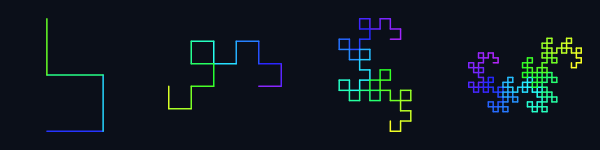

In [4]:
def orders(t):
    t.pensize(2)
    for k, order in enumerate((2, 4, 6, 8)):
        draw_curve(t, points(order), 150, -300 + k * 200)


render(orders, 800, 200, dpi=54)

## Order 13

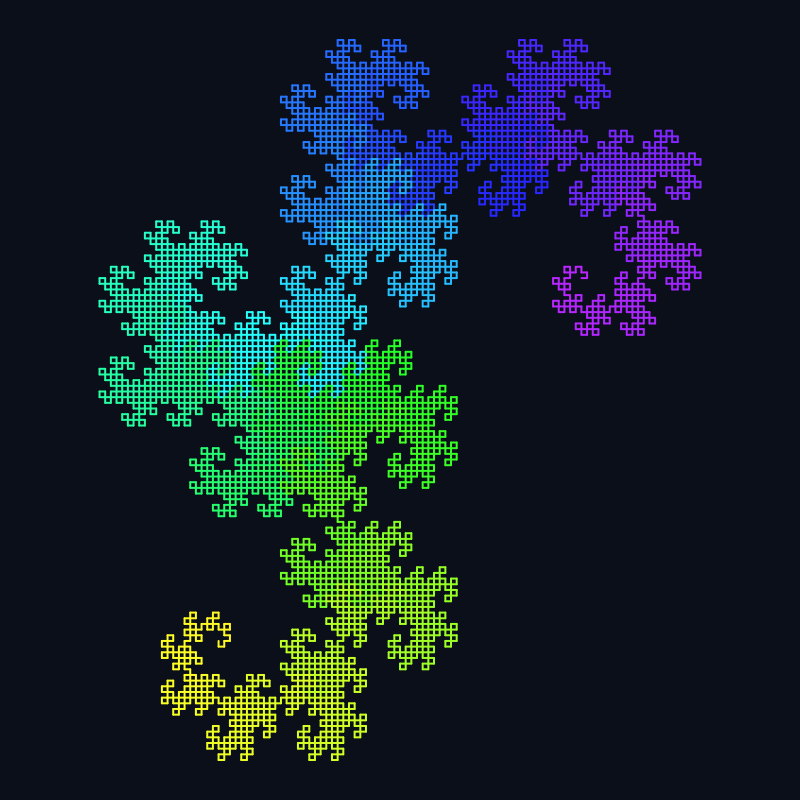

In [5]:
ORDER = 13
FIT = 720  # longest side of the curve in px


def draw(t):
    t.pensize(2)
    draw_curve(t, points(ORDER), FIT)


render(draw)

## Try

- `ORDER = 16`: 65,536 segments, still only a few seconds.
- `hsv(4 * i / len(pts), …)` runs through the rainbow four times along the curve.
- Draw four copies from the same start point, each rotated a quarter turn (map every point
  `(x, y)` to `(-y, x)` between copies, and skip the centering), and see how they fit together.